In [84]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
%matplotlib inline

In [85]:
url_red = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'
df_red = pd.read_csv(url_red, sep=';')

url_white = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv'
df_white = pd.read_csv(url_red, sep=';')

df_red['is_red'] = 1
df_white['is_red'] = 0

df = pd.concat([df_red, df_white], ignore_index=True)

print(df.shape)
df.head()

(3198, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


In [86]:
f'{round(float(df.duplicated().sum() / df.shape[0]), 2) * 100} %'

'15.0 %'

In [87]:
stats = df.describe().T[['mean', 'std', 'min', '50%', 'max']]
stats['skew'] = df.skew()
stats['kurtosis'] = df.kurtosis()
stats

,mean,std,min,50%,max,skew,kurtosis
fixed acidity,8.319637,1.740824,4.60000,7.90000,15.90000,0.982290,1.128496
volatile acidity,0.527821,0.179032,0.12000,0.52000,1.58000,0.671277,1.221748
citric acid,0.270976,0.194771,0.00000,0.26000,1.00000,0.318188,-0.789641
residual sugar,2.538806,1.409708,0.90000,2.20000,15.50000,4.538524,28.570964
chlorides,0.087467,0.047058,0.01200,0.07900,0.61100,5.677680,41.648672
free sulfur dioxide,15.874922,10.458521,1.00000,14.00000,72.00000,1.249980,2.018520
total sulfur dioxide,46.467792,32.890179,6.00000,38.00000,289.00000,1.514820,3.801989
density,0.996747,0.001887,0.99007,0.99675,1.00369,0.071254,0.930741
pH,3.311113,0.154362,2.74000,3.31000,4.01000,0.193593,0.803803
sulphates,0.658149,0.169480,0.33000,0.62000,2.00000,2.427532,11.700044


In [88]:
X = df.drop(columns=['quality'])
y = df['quality']

<Axes: xlabel='quality', ylabel='Count'>

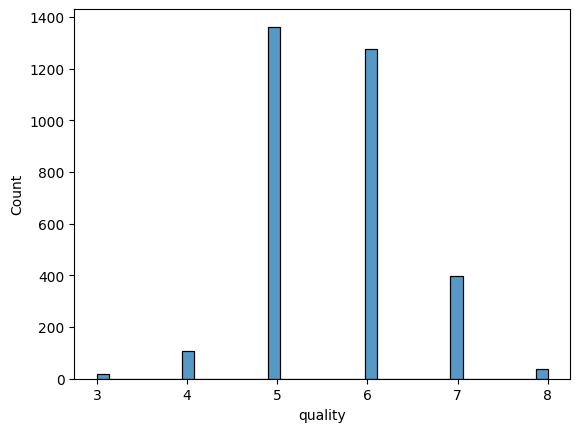

In [89]:
sns.histplot(y)

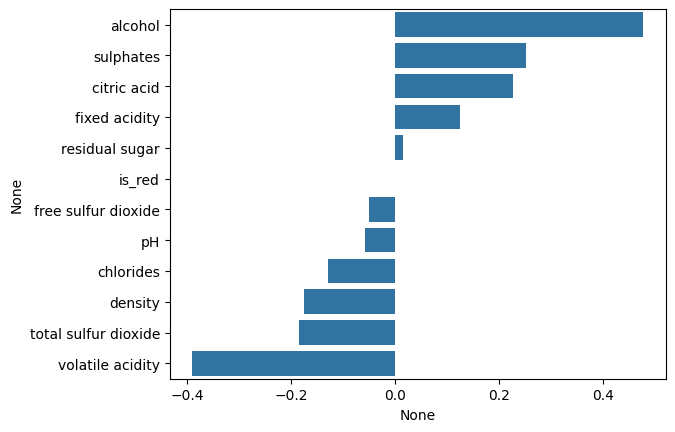

In [90]:
correlations = X.corrwith(y).sort_values(ascending=False)

plot = sns.barplot(y=correlations.index, x=correlations)

<Axes: >

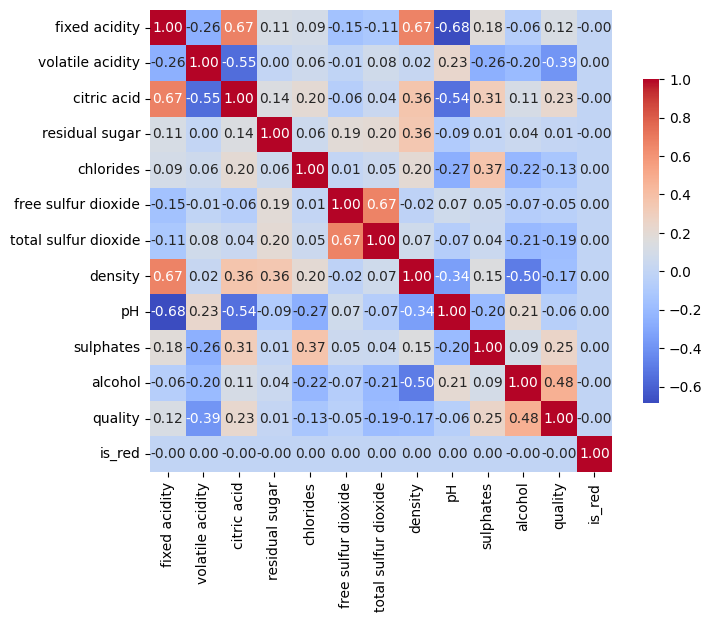

In [91]:
corr_matrix = df.corr()
plt.figure(figsize=(8,6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', square=True, cbar_kws={'shrink': 0.7})

In [92]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
scaler.fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [121]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

models = {
    'Baseline': DummyRegressor(strategy='mean'),
    'LinearRegression': LinearRegression(),
    'RandomForestRegressor': RandomForestRegressor(),
    'GradientBoostingClassifier': GradientBoostingRegressor()
}

rows = []
coefs = []

for name, model in models.items():
  model.fit(X_train_scaled, y_train)
  pred = model.predict(X_test_scaled)
  train_pred = model.predict(X_train_scaled)
  if hasattr(model, 'coef_'):
    coefs.append({'model': name, 'coef': model.coef_})
  elif hasattr(model, 'feature_importances_'):
    coefs.append({'model': name, 'coef': model.feature_importances_})
  rows.append({
      'model': name,
      'test RMSE': root_mean_squared_error(y_test, pred),
      'train RMSE': root_mean_squared_error(y_train, train_pred),
      'MAE': mean_absolute_error(y_test, pred),
  })

results = pd.DataFrame(rows).sort_values("test RMSE")
results




,model,test RMSE,train RMSE,MAE
2,RandomForestRegressor,0.316123,0.118038,0.184250
3,GradientBoostingClassifier,0.538998,0.499639,0.417336
1,LinearRegression,0.625569,0.651147,0.490317
0,Baseline,0.786806,0.812606,0.671753


In [122]:
for models in coefs:
  name = models['model']
  coef = models['coef']
  print(name, coef)



LinearRegression [ 0.03434204 -0.20515553 -0.02844463  0.02138187 -0.0914858   0.02903364
 -0.08935234 -0.02766552 -0.05222768  0.1504013   0.29671478 -0.01029204]
RandomForestRegressor [0.04753894 0.14690268 0.0465985  0.05680274 0.06561051 0.04511143
 0.07784964 0.04973667 0.05614579 0.12979189 0.27723786 0.00067336]
GradientBoostingClassifier [3.89365945e-02 1.77996891e-01 2.57436255e-02 2.96506916e-02
 3.88382349e-02 1.88670945e-02 8.12752467e-02 2.64966928e-02
 2.57178862e-02 1.55525853e-01 3.80951189e-01 6.80830025e-16]
